# Classifying Online Shopper Purchase Intention

This notebook predicts the UCI `Revenue` label with logistic regression. The stratified holdout is created before scaling or one-hot encoding, and every learned transformation is fitted only on training rows through a scikit-learn pipeline.

In [1]:
import json
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, average_precision_score, classification_report, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
sns.set_theme(style='whitegrid')
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00468/online_shoppers_intention.csv'
shopping = pd.read_csv(url).dropna().copy()
shopping['Revenue'] = shopping['Revenue'].astype(int)
print(shopping.shape, shopping['Revenue'].value_counts(normalize=True))

(12330, 18) Revenue
0    0.845255
1    0.154745
Name: proportion, dtype: float64


## Explore the imbalanced outcome

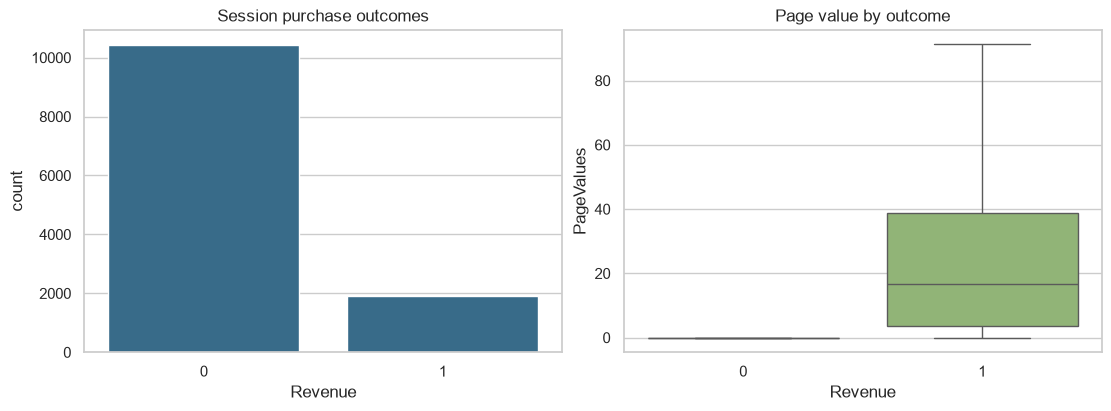

In [2]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
sns.countplot(data=shopping, x='Revenue', color='#2a6f97', ax=axes[0]); axes[0].set_title('Session purchase outcomes')
sns.boxplot(data=shopping, x='Revenue', y='PageValues', color='#90be6d', showfliers=False, ax=axes[1]); axes[1].set_title('Page value by outcome')
plt.show()

## Build a train-only preprocessing pipeline

In [3]:
X = shopping.drop(columns='Revenue')
y = shopping['Revenue']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.30, stratify=y, random_state=SEED)
categorical = ['Month', 'VisitorType', 'Weekend', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']
numeric = [column for column in X.columns if column not in categorical]
preprocessor = ColumnTransformer([('numeric', StandardScaler(), numeric), ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical)])
model = Pipeline([('preprocessor', preprocessor), ('classifier', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=SEED))])
baseline = DummyClassifier(strategy='prior')
model.fit(X_train, y_train); baseline.fit(X_train, y_train)
predictions = model.predict(X_test); probabilities = model.predict_proba(X_test)[:, 1]
baseline_probabilities = baseline.predict_proba(X_test)[:, 1]
metrics = {'rows': len(shopping), 'positive_share': y.mean(), 'roc_auc': roc_auc_score(y_test, probabilities), 'average_precision': average_precision_score(y_test, probabilities), 'f1': f1_score(y_test, predictions), 'baseline_roc_auc': roc_auc_score(y_test, baseline_probabilities)}
print(classification_report(y_test, predictions, target_names=['no purchase', 'purchase'], digits=3))

              precision    recall  f1-score   support

 no purchase      0.950     0.869     0.908      3127
    purchase      0.512     0.750     0.609       572

    accuracy                          0.851      3699
   macro avg      0.731     0.810     0.758      3699
weighted avg      0.882     0.851     0.862      3699



## Evaluate probabilities and thresholded predictions

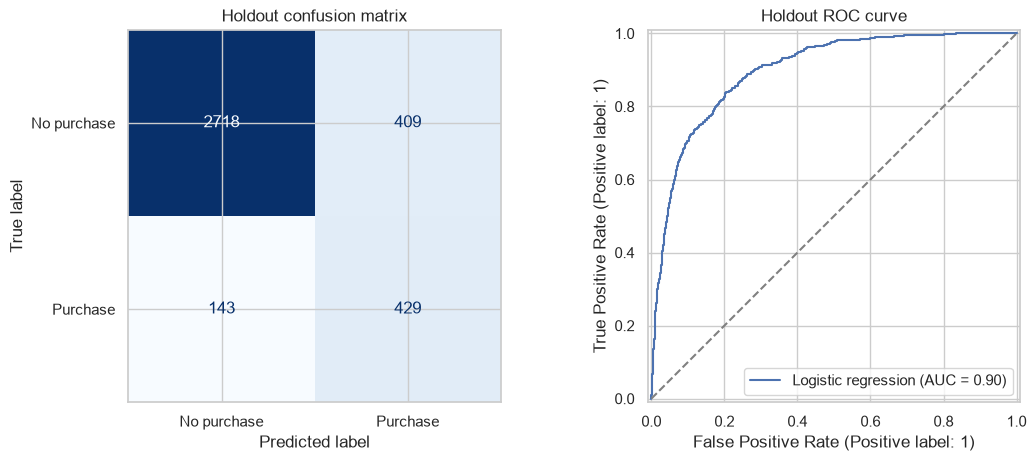

In [4]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4.5), constrained_layout=True)
ConfusionMatrixDisplay.from_predictions(y_test, predictions, display_labels=['No purchase', 'Purchase'], cmap='Blues', colorbar=False, ax=axes[0])
axes[0].set_title('Holdout confusion matrix')
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay
RocCurveDisplay.from_predictions(y_test, probabilities, name='Logistic regression', ax=axes[1])
axes[1].plot([0, 1], [0, 1], '--', color='gray'); axes[1].set_title('Holdout ROC curve')
plt.show()

## Inspect holdout permutation importance

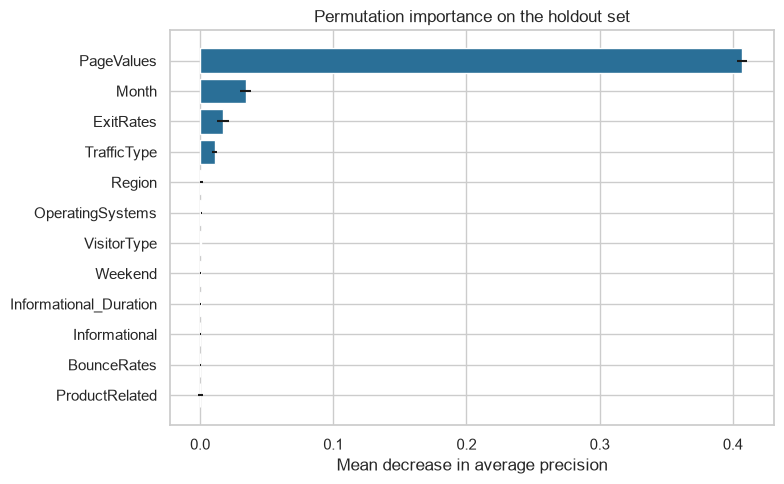

RESULT_JSON={"rows": 12330, "positive_share": 0.15474452554744525, "roc_auc": 0.8982195450855509, "average_precision": 0.6300503021738386, "f1": 0.6085106382978723, "baseline_roc_auc": 0.5, "top_feature": "PageValues"}


In [5]:
importance = permutation_importance(model, X_test, y_test, scoring='average_precision', n_repeats=10, random_state=SEED, n_jobs=1)
importance_frame = pd.DataFrame({'feature': X.columns, 'mean_ap_decrease': importance.importances_mean, 'std': importance.importances_std}).sort_values('mean_ap_decrease').tail(12)
figure, ax = plt.subplots(figsize=(8, 5)); ax.barh(importance_frame['feature'], importance_frame['mean_ap_decrease'], xerr=importance_frame['std'], color='#2a6f97')
ax.set(title='Permutation importance on the holdout set', xlabel='Mean decrease in average precision'); plt.tight_layout(); plt.show()
metrics['top_feature'] = importance_frame.iloc[-1]['feature']
print('RESULT_JSON=' + json.dumps(metrics))

## Limitations

The data records sessions, not unique people, and the label is strongly imbalanced. A random holdout does not test seasonality or repeated visitors. The balanced class weights change the default decision trade-off, so a store should select a threshold from intervention costs and validate it on a later time period. Permutation importance is predictive, not causal.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.

### Reproducibility note

This retained cell replaces a legacy exploratory step. The executable workflow above contains the synchronized model, evaluation, and limitations.